# 21 The I2t winding estimate

Notebook 19 graded the winding thermometer that shipped in `estimator::thermal`, a resistance
thermometer with seats, reference windows and a carry model between them. It read the winding to
about a degree when it worked, and it took 1250 lines of firmware and four kernel stages to do it.
The firmware's job is to keep the winding under its limit, and a winding temperature on the screen
is a nice extra. So the thermometer is coming out, and one multiply replaces it.

The kernel already keeps an I2t budget for the current limit, a leaky sum of the current squared.
That sum is the winding's excess temperature in disguise. Add it to the board NTC with one user
constant and you have a winding estimate. This notebook replays that estimate over the heating
holds already on disk, fits its two constants for the two places the NTC can sit, and grades it
against the winding read through its own copper. Nothing here needed the bench.

If you are short on time, here is the quick version. With the NTC on the can (where it sits on a
swap board) the estimate holds the winding within 3.6 C either way over eight and ten minute holds
at the rating, with a 16.4 s leak. With the NTC on a board in room air (the dev board) the fit wants
a 78.2 s leak and the firmware runs the nearest octave, 65.5 s. That estimate reads at most 0.4 C
cold and 4.3 C warm, and 2.74 C of the warm side is the board NTC reading over the can at rest, before the
hold began. The constants are in section 6.

## Picking a rig

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import oscnb
from oscnb import boards, datasets, servos, thermal as th, thermometer as tm, heating as ht, i2t

# Both datasets came off rev 2A board #1 with the bench MG90. The thermometer dataset carries no
# sense block (notebook 19 says why), so the board is named by hand, as there.
board, servo = boards.BOARDS["dev-v006-2A"], servos.SERVOS["mg90-a"]
rig = oscnb.Rig(board, servo).show()

DS = datasets.load("mg90-a__dev-v006-2A__dps__thermometer")   # the two `osc ident thermal` holds (DPS, board NTC logged)
H = datasets.load("mg90-a__dev-v006-2A__2s__heating")         # the locked-rotor hold (2S, bead on the can, NTC dead)
IX = tm.index(DS).set_index("capture")

K_CU = th.T0_CU                                               # copper: R is proportional to (234.5 + T)
OHM = board.v_term_per_count / board.a_per_count              # ohm per vcount/ccount


def thermal_tau_s(shift):
    # the thermal_tau_s a user writes to land on an octave: the field holds whole seconds, so the
    # octave's time constant rounded to the nearest one, which the firmware rounds back to the octave
    return round(i2t.tau_s(shift))


NAME = {"can": "can", "ntc": "board NTC"}                     # the two bases, by name


def rng(lo, hi, f):
    # "lo to hi" in format f, or one number when a single run gives both ends
    a, b = format(lo, f), format(hi, f)
    return a if a == b else f"{a} to {b}"


pd.set_option("display.width", 160)

Vorpal MG90 clone, unit A on osc-dev-v006 rev 2A, board #1

  board: Rs1 60 mOhm; bare OPA with Rf 6k4 / Rg 430 (G 14.884), Cc 22 pF, Co1 DNP. Terminal taps Rv1/Rv3 6k4 over Rv2/Rv4 1k6 with Cv1/Cv2 100 pF, bottoms and caps returned to VB from Rb1 430 / Rb2 100 (773 counts nominal, about 81 ohm source, so VB rises with the leg current under drive). VSNS 6k4/1k6 to GND, unbiased, Cv3 100 pF. A 2A capture's sense block differs from board D's in gain_milli and both divider legs. Nothing in the block carries the bias or VSNS parts, or which 2A unit took the capture, so every 2A board shares this entry. Board #1 had Rv3 open for the grid-3r7 2S session: in that dataset tap B reads the VB node instead of terminal B, so only tap A, the rail and the current are graded there. Rv3 is repaired, and a dataset captured with it fitted reads both taps. Floors 64/93 ticks: the current at 3% with the settle gain on top (nb10 sec 8), the terminals from the grid ladder with tap B sampled 37 ticks before 

value
where            quantity                                           unit                          
board            converter step                                     mV per count            0.8057
                 terminal divider ratio r                                                   5.0000
                 terminal difference                                mV per count            4.0283
                 terminal bias VB                                   mV                    622.6415
                                                                    counts                772.8302
                 driven-low terminal reads                          counts                618.2642
                 motor current                                      mA per count            0.9022
                                                                    counts per A         1108.4521
                 shunt                                              mOhm                   60.0000
                 amplifier gain                                     x                      14.8840
                 rail tap ratio                                                             5.0000
                 sample rate                                        samples per ms         20.0000
                 current settled from                               % duty                  5.3333
                 voltage settled from                               % duty                  7.7500
servo            pot intercept                                      counts                209.0000
                 pot slope                                          counts per degree      19.7600
                 envelope low                                       counts (15.74 deg)    520.0224
                 envelope high                                      counts (168.59 deg)  3540.3384
                 runway                                             counts               3020.3160
                 seek guard low                                     counts                520.0000
                 seek guard high                                    counts               3540.0000
servo (measured) gear_ratio_measured [308.053, 308.053] mechanic... :1                    308.0533
                 ripple_order_measured [6, 6] teardown, 3-slot b... per motor rev           6.0000
                 r_winding_measured [4.49, 4.98] bringup capture... Ohm                     4.8900
                 ke_ripple_measured [1.284, 1.306] nb09 sec 3, s... mV per ripple Hz        1.2950
                 pot_scale_measured [19.7, 19.85] nb09 sec 10, r... counts/deg             19.7600
                 travel_measured [178.67, 189.18] nb09 sec 10, p... deg                   184.2200
                 low_stop_after_stall_measured [232, 236] hand s... counts                232.0000
                 backlash_measured [1.25, 1.5] nb09 sec 4, rever... ripple cycles           1.4800

## 1. The estimate

Every 16 ms (the kernel's SLOW period) the I2t budget leaks the square of the held current into a
heat state. In the firmware's integers that is

$$\text{heat} \mathrel{+}= (i^2 - \text{heat}) \gg s$$

with $i$ in current counts and $s$ the leak as a power of two of SLOW periods, so the time constant
is $\tau = 16\,\text{ms} \cdot 2^s$. The user writes `thermal_tau_s` in whole seconds and the firmware
rounds it to the nearest octave, at most $2^{14}$ periods, which is 262 s. An octave's time
constant is not a whole number of seconds, so the table below prints the whole second that lands
on each one. The estimate is then

$$\hat T_w = T_\text{ntc} + k \cdot \text{heat}$$

where $k$ is a rise constant in centi-C per count squared, carried as Q0.16. Physically $k$ is the
thermal resistance from the winding to wherever the NTC sits, times the winding's resistance, times
the square of the board's amps per count, so a user who knows the motor's K/W can write it, and a
user who does not can run the heating hold this notebook replays.

What the one leak cannot do is follow two time constants. The winding over the can is fast (tens
of seconds) and the can over the air is slow (notebook 18's 129 s). With the NTC on the can the
leak only has to carry the fast node. With the NTC on a board in room air it has to carry both
with one number, and section 3 shows what that costs.

`oscnb.i2t` is the replay. `heat` runs the kernel's integer arithmetic exactly (the guard bits, the
capped square, the arithmetic shift), `rise_cc` reads the rise and saturates it at the i16 ceiling
as the kernel does, `ewma` is the same leak in floats at any time constant, and `grid` puts a
capture's current polls on the 16 ms grid the way the kernel sees them, holding the last poll.

In [2]:
# the leak octaves the firmware can run, the time constant each one lands on, and the
# thermal_tau_s that selects it (read back through the firmware's rounding as a check)
octaves = pd.DataFrame({"shift": range(6, i2t.TAU_SHIFT_MAX + 1)})
octaves["tau_s"] = [i2t.tau_s(s) for s in octaves["shift"]]
octaves["thermal_tau_s"] = [thermal_tau_s(s) for s in octaves["shift"]]
octaves["rounds to shift"] = [i2t.tau_shift(s) for s in octaves.thermal_tau_s]
display(octaves.set_index("shift"))
print(f"the boot default 4 s runs at shift {i2t.tau_shift(4)} ({i2t.tau_s(i2t.tau_shift(4)):.1f} s)")
print(f"66 s is {66 * 1000 // i2t.SLOW_MS} SLOW periods, past 1.5 x 2^11 = {3 * 2 ** 10}, so it rounds to shift "
      f"{i2t.tau_shift(66)}")
# the firmware rounds up only above 1.5 x 2^k periods, so the last whole second at or under
# 1.5 x 2^k periods lands on the octave below
w = int(1.5 * i2t.tau_s(8))
print(f"at the edge of the boot default's octave: {w} s written runs at {i2t.tau_s(i2t.tau_shift(w)):.1f} s, "
      f"a factor of {w / i2t.tau_s(i2t.tau_shift(w)):.2f}")

,tau_s,thermal_tau_s,rounds to shift
shift,,,
6,1.024,1,6
7,2.048,2,7
8,4.096,4,8
9,8.192,8,9
10,16.384,16,10
11,32.768,33,11
12,65.536,66,12
13,131.072,131,13
14,262.144,262,14


the boot default 4 s runs at shift 8 (4.1 s)
66 s is 4125 SLOW periods, past 1.5 x 2^11 = 3072, so it rounds to shift 12
at the edge of the boot default's octave: 6 s written runs at 4.1 s, a factor of 1.46


## 2. The holds and the truth

Three holds at the current limit sit on disk, all on the same motor and board.

- `thermal/capture-1` and `thermal/capture-2` of the thermometer dataset. 480 s seated at the low
  stop at 280 counts on the DPS, the identification aggregates (current, terminal difference, duty)
  every 22 ms, the K bead on the can, and for capture-2 the board NTC in the polls. Capture-1 has no
  NTC in its polls (the tool did not log it yet), only in the rest log before the hold.
- `hold/capture-1` of the heating dataset. A 600 s locked-rotor hold at the low stop on the 2S pack,
  the same aggregates, the bead on the can in every poll, the board NTC dead that night.

The truth is the winding read through its own copper. The aggregates give the winding's resistance
as $R = d \cdot v_\text{diff} / i$ through the board's volts and amps per count ($d$ the applied duty),
the same ratio `osc ident resistance` reads. Each hold starts at $t_0$, the first poll at the hold's
duty. The ident holds seek the stop at a lower duty first and their polls carry no phase marker, so
there $t_0$ is the first poll whose applied duty steps past the seek's. The heating hold marks its
phase in the polls, and $t_0$ is its first hold poll. Every time axis below is seconds after $t_0$.
I take the reference $R_\text{ref}$ over 1 to 3 s after $t_0$, the way the shipped thermometer did
(the brush contact settles through the first second), and read the winding from then on as

$$T_w = T_{w0} + \left(\frac{R}{R_\text{ref}} - 1\right)(234.5 + T_{w0})$$

with $T_{w0}$ the can over the 5 s before $t_0$. The heating hold's file starts at $t_0$, so its
window holds the one poll at $t_0$. The servo rested for ten minutes before each hold, so winding,
can and board should sit at one temperature then. They do not quite. Notebook 19 measured the
board NTC over the can by 2.0 to 2.75 C at rest and could not say which of the two is off. I start
the truth at the can and use the NTC as the firmware's base, which is what the firmware will do.

The two placements come out of the same holds. The excess over the can, $T_w - T_\text{can}$, is what
an NTC on the can would have to carry. The excess over the board NTC, $T_w - T_\text{ntc}$, is what
the dev board's NTC has to carry, and it starts at the two sensors' rest disagreement. Only
capture-2 can grade the second.

In [3]:
def ident_hold(capture):
    # The `osc ident thermal` hold: aggregates in anchor.csv.gz (t_ms from the run's start), the
    # tool's polls in anchor_snapshots.csv.gz (host_ms, the same clock), the bead in meter.csv.gz (unix).
    a = tm._csv(DS.path / capture / "anchor.csv.gz")
    a["t"] = a.t_ms / 1000
    a["r"] = (a.duty_q15.abs() / 32767) * (a.vdiff / a.i) * OHM      # the aggregate R, ohm
    s = tm._csv(DS.path / capture / "anchor_snapshots.csv.gz")
    s["t"] = s.host_ms / 1000
    # t0, the hold's start. The polls carry no phase marker and the seek to the stop already drives
    # (its duty is the first nonzero one), so t0 is the first poll whose applied duty steps past the
    # seek's: the hold's duty, with the current limit governing.
    duty = s.duty_applied_q15.abs()
    seek = duty[duty > 0].iloc[0]
    t0 = float(s.t[duty > seek].iloc[0])
    t1 = float(a.t.max())
    m, u0 = tm.meter(DS, capture), IX.loc[capture, "unix0"]
    tt = np.arange(2.0, t1 - t0, 1.0)                                  # the truth on a 1 s grid, s into the hold
    ta = t0 + tt                                                       # the same grid on the run's clock
    r = np.array([a[(a.t >= x - 0.5) & (a.t < x + 0.5)].r.mean() for x in ta])
    r_ref = a[(a.t >= t0 + 1) & (a.t < t0 + 3)].r.mean()             # 1 to 3 s into the hold
    can = tm.can_at(m, u0 + ta, 3.0)
    # the rest values, over the 5 s before the hold current: the can is the winding's start and the
    # can base's start, the NTC polls (from the run's start, so 0 to t0) the NTC base's start
    tw0 = float(m[(m.t_unix >= u0 + t0 - 5) & (m.t_unix < u0 + t0)].can_c.mean())
    ntc, ntc0 = None, None
    if "t_ntc_cc" in s:
        ntc = np.array([s[(s.t >= x - 2.5) & (s.t < x + 2.5)].t_ntc_cc.mean() / 100 for x in ta])
        ntc0 = float(s[(s.t >= t0 - 5) & (s.t < t0)].t_ntc_cc.mean() / 100)
    # the kernel's view of the current from t0; the aggregates start about 0.1 s after t0, and
    # the grid reads zero current until the first one
    tg, ig = i2t.grid(a.t.to_numpy(), a.i.abs().to_numpy(), t0, t1)
    p = float((a.r * (a.i * board.a_per_count) ** 2).mean())
    return dict(t0=t0, tt=tt, r=r, r_ref=r_ref, tw0=tw0, tw=tw0 + (r / r_ref - 1) * (K_CU + tw0),
                can=can, ntc=ntc, base0={"can": tw0, "ntc": ntc0}, tg=tg - t0, ig=ig,
                i=float(a.i.abs().mean()), p=p)


def locked_hold():
    # The heating dataset's locked-rotor hold: polls with the aggregates and the bead inline, the
    # hold phase marked, so t0 is the first poll of the hold phase.
    h_all = ht.hold(H, "hold/capture-1", board)
    h = h_all[h_all.phase == "hold"]
    t0, t1 = float(h.t_s.min()), float(h.t_s.max())
    tt = np.arange(2.0, t1 - t0, 1.0)                                  # s into the hold
    ta = t0 + tt
    r = np.array([h[(h.t_s >= x - 0.5) & (h.t_s < x + 0.5)].r_agg.mean() for x in ta])
    r_ref = h[(h.t_s >= t0 + 1) & (h.t_s < t0 + 3)].r_agg.mean()
    can = np.array([h[(h.t_s >= x - 3) & (h.t_s < x + 3)].can_c.mean() for x in ta])
    # the same 5 s rest window as the ident holds; the file starts at the hold, so the window
    # holds the one poll at t0
    tw0 = float(h_all[(h_all.t_s >= t0 - 5) & (h_all.t_s <= t0)].can_c.mean())
    tg, ig = i2t.grid(h.t_s.to_numpy(), h.i_hat.abs().to_numpy(), t0, t1)
    return dict(t0=t0, tt=tt, r=r, r_ref=r_ref, tw0=tw0, tw=tw0 + (r / r_ref - 1) * (K_CU + tw0),
                can=can, ntc=None, base0={"can": tw0, "ntc": None}, tg=tg - t0, ig=ig,
                i=float(h.i_hat.abs().mean()), p=float((h.r_agg * h.i_a ** 2).mean()))


RUNS = {"thermal/capture-1": ident_hold("thermal/capture-1"),
        "thermal/capture-2": ident_hold("thermal/capture-2"),
        "heating hold": locked_hold()}

rows = []
for name, R in RUNS.items():
    rows.append({"run": name, "t0 s": R["t0"], "i counts": R["i"], "P W": R["p"], "R_ref ohm": R["r_ref"],
                 "T_w0 C": R["tw0"], "NTC at rest C": R["base0"]["ntc"],
                 "winding rise C": R["tw"][-1] - R["tw0"],
                 "can rise C": R["can"][-1] - R["tw0"],
                 "NTC rise C": np.nan if R["ntc"] is None else R["ntc"][-1] - R["base0"]["ntc"],
                 "end excess over can C": R["tw"][-1] - R["can"][-1],
                 "end excess over NTC C": np.nan if R["ntc"] is None else R["tw"][-1] - R["ntc"][-1]})
HOLDS = pd.DataFrame(rows).set_index("run")
display(HOLDS.round(3))

,t0 s,i counts,P W,R_ref ohm,T_w0 C,NTC at rest C,winding rise C,can rise C,NTC rise C,end excess over can C,end excess over NTC C
run,,,,,,,,,,,
thermal/capture-1,1.436,266.115,0.269,4.500,25.6,NaN,10.846,8.1,NaN,2.746,NaN
thermal/capture-2,1.434,262.555,0.260,4.449,25.4,28.137,11.845,8.2,1.219,3.645,7.889
heating hold,33.740,264.816,0.274,4.595,27.0,NaN,11.122,6.5,NaN,4.622,NaN


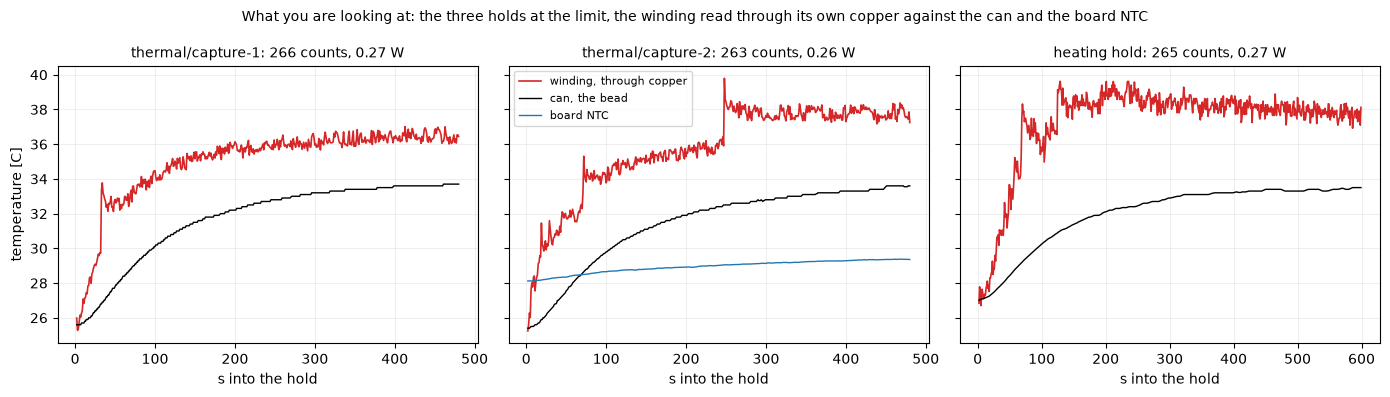

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, R) in zip(axes, RUNS.items()):
    ax.plot(R["tt"], R["tw"], color="tab:red", lw=1.2, label="winding, through copper")
    ax.plot(R["tt"], R["can"], color="k", lw=1, label="can, the bead")
    if R["ntc"] is not None:
        ax.plot(R["tt"], R["ntc"], color="tab:blue", lw=1, label="board NTC")
    ax.set_title(f"{name}: {R['i']:.0f} counts, {R['p']:.2f} W", fontsize=10)
    ax.set_xlabel("s into the hold")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("temperature [C]")
axes[1].legend(fontsize=8)                                       # capture-2 carries all three traces
fig.suptitle("What you are looking at: the three holds at the limit, the winding read through its own copper "
             "against the can and the board NTC", fontsize=10)
plt.tight_layout()
plt.show()

In [5]:
# what the copper reading does before any fit, run by run
C_W = (1.3, 0.7)                     # notebook 18's winding heat capacity bracket, J/C
for name, R in RUNS.items():
    tt, r, tw = R["tt"], R["r"], R["tw"]
    step = np.diff(r) / r[:-1] * 100                                  # the change of R from one second to the next, %
    j = int(np.nanargmax(np.abs(step)))
    over = tw - R["can"]                                              # the winding's excess over the can, C
    k = int(np.nanargmax(over))
    k120 = int(np.nanargmax(np.where(tt <= 120, over, -np.inf)))
    early = (tt >= 2) & (tt <= 10)
    rise = tw[early][-1] - tw[early][0]                               # the copper's rise from 2 to 10 s
    dt = tt[early][-1] - tt[early][0]
    print(f"{name}: hold from {R['t0']:.2f} s into the run; largest 1 s step of R {step[j]:+.2f} % at {tt[j + 1]:.0f} s "
          f"({step[j] / 100 * (K_CU + R['tw0']):+.1f} C of copper); excess over the can peaks at {over[k]:.1f} C at "
          f"{tt[k]:.0f} s ({over[k120]:.1f} C at {tt[k120]:.0f} s inside the first 120 s) and ends at {over[-1]:.1f} C; the copper rises {rise:.2f} C from {tt[early][0]:.0f} to "
          f"{tt[early][-1]:.0f} s, where {R['p']:.3f} W into {C_W[0]} to {C_W[1]} J/C with no loss allows "
          f"{R['p'] * dt / C_W[0]:.2f} to {R['p'] * dt / C_W[1]:.2f} C")
R2 = RUNS["thermal/capture-2"]
print(f"capture-2: the NTC rose {HOLDS.loc['thermal/capture-2', 'NTC rise C']:.2f} C over the hold while the winding "
      f"rose {HOLDS.loc['thermal/capture-2', 'winding rise C']:.2f} C; at rest the NTC read "
      f"{R2['base0']['ntc'] - R2['tw0']:+.2f} C against the can")

thermal/capture-1: hold from 1.44 s into the run; largest 1 s step of R +1.37 % at 33 s (+3.6 C of copper); excess over the can peaks at 6.9 C at 34 s (6.9 C at 34 s inside the first 120 s) and ends at 2.7 C; the copper rises 1.10 C from 2 to 10 s, where 0.269 W into 1.3 to 0.7 J/C with no loss allows 1.65 to 3.07 C
thermal/capture-2: hold from 1.43 s into the run; largest 1 s step of R +1.44 % at 248 s (+3.7 C of copper); excess over the can peaks at 7.3 C at 248 s (6.7 C at 72 s inside the first 120 s) and ends at 3.6 C; the copper rises 3.17 C from 2 to 10 s, where 0.260 W into 1.3 to 0.7 J/C with no loss allows 1.60 to 2.97 C
heating hold: hold from 33.74 s into the run; largest 1 s step of R +0.95 % at 125 s (+2.5 C of copper); excess over the can peaks at 9.1 C at 70 s (9.1 C at 70 s inside the first 120 s) and ends at 4.6 C; the copper rises 0.29 C from 2 to 10 s, where 0.274 W into 1.3 to 0.7 J/C with no loss allows 1.69 to 3.13 C
capture-2: the NTC rose 1.22 C over the hold wh

Three things stand out before any fit. The copper reading steps, once or several times per hold.
The largest one-second step is 1.37 % of R at 33 s in capture-1, 1.44 % at 248 s in capture-2 (the
one the old thermometer's gate flagged as G3 in the dataset notes) and 0.95 % at 125 s in the
heating hold, 2.5 to 3.7 C of copper. Notebook 19 traced steps like these to the brush contact.
They stay in the truth here, because I have no honest way to take them out, and they set a floor
under any grade.

The winding's excess over the can peaks inside the first two minutes, at 6.9 C at 34 s in
capture-1, 6.7 C at 72 s in capture-2 and 9.1 C at 70 s in the heating hold. It then falls back to
2.7 to 4.6 C at the end while the can keeps rising. A two-node plant does not do that, since its
fast node rises and stays. In capture-1 the peak sits one second after the largest step of R, so
part of it is contact. Capture-2's highest excess over the whole hold, 7.3 C, sits on its 248 s
step.

The first seconds mostly stay inside what the winding's heat capacity allows. From 2 to 10 s the
copper rises 1.10 C in capture-1 and 0.29 C in the heating hold. With no heat leaving, the hold's
power into notebook 18's bracket of 1.3 down to 0.7 J/C allows 1.65 to 3.07 C and 1.69 to 3.13 C
there. Capture-2 rises 3.17 C against an allowance of 1.60 to 2.97 C, just over the top of it.
Section 7 takes the peaks and capture-2's early rise up. For the grade the peaks matter most, since
the estimate with one leak reads coldest on them.

On the dev board the NTC rose 1.22 C over the hold while the winding rose 11.85 C, and at rest it
read 2.74 C over the can. The board's own NTC is nearly a room thermometer there, so the estimate's
rise term has to carry almost everything.

## 3. Fitting k and tau

For each run and each base I run the heat at every leak octave from shift 6 to shift 12 (1 to 65.5 s), and once
more in floats at a free time constant, and fit the one $k$ that best matches the truth by least
squares. The fit target is the winding's rise since rest less the base's rise since rest,

$$x = (T_w - T_{w0}) - (T_\text{base} - T_\text{base,0})$$

with $T_\text{base,0}$ the base over the same 5 s before $t_0$ as $T_{w0}$. For the can base that
is the plain excess over the can. For the board NTC it takes out the NTC's reading over the can at
rest, which a fit through the origin would otherwise fold into $k$. The grade in section 4 puts
that offset back, since the firmware's base carries it. The table reads the residual sd and the
signed extremes of the error against $x$ (estimate minus target), in C. Negative is the estimate
reading cold, which is the side protection cares about.

In [6]:
def excess_rise(R, base):
    # the fit target: the winding's rise since rest less the base's rise since rest, C. Taking
    # rise over rise keeps the two sensors' rest disagreement out of k.
    return (R["tw"] - R["tw0"]) - (R[base] - R["base0"][base])


def fits(name, base):
    R = RUNS[name]
    if R[base] is None:
        return []
    x = excess_rise(R, base)
    out = []
    for shift in range(6, 13):
        hq = i2t.heat(R["ig"].astype(np.int64), shift)       # the kernel's integer heat state
        hat = np.interp(R["tt"], R["tg"], hq)
        k, sd = i2t.fit_k(hat, x * 100)
        lo, hi, rms = i2t.grade(k * hat / 100, x)
        out.append(dict(run=name, base=base, shift=shift, tau_s=i2t.tau_s(shift), k=k, k_q16=i2t.k_q16_of(k),
                        sd_C=sd, cold_C=lo, warm_C=hi))
    best = None
    for tau in np.geomspace(4, 400, 80):                     # the free leak, floats
        hat = np.interp(R["tt"], R["tg"], i2t.ewma(R["ig"] ** 2, tau, i2t.SLOW_S))
        k, sd = i2t.fit_k(hat, x * 100)
        if best is None or sd < best[1]:
            best = (tau, sd, k, hat)
    lo, hi, rms = i2t.grade(best[2] * best[3] / 100, x)
    out.append(dict(run=name, base=base, shift="free", tau_s=best[0], k=best[2], k_q16=i2t.k_q16_of(best[2]),
                    sd_C=best[1], cold_C=lo, warm_C=hi))
    return out


FITS = pd.DataFrame(sum((fits(n, b) for n in RUNS for b in ("can", "ntc")), []))
print(FITS.round({"tau_s": 1, "k": 5, "sd_C": 2, "cold_C": 2, "warm_C": 2}).to_string())

                  run base shift  tau_s        k  k_q16  sd_C  cold_C  warm_C
0   thermal/capture-1  can     6    1.0  0.00462    303  0.83   -3.55    3.67
1   thermal/capture-1  can     7    2.0  0.00464    304  0.81   -3.51    3.24
2   thermal/capture-1  can     8    4.1  0.00466    306  0.77   -3.47    2.46
3   thermal/capture-1  can     9    8.2  0.00472    309  0.71   -3.46    1.66
4   thermal/capture-1  can    10   16.4  0.00478    314  0.70   -3.78    1.04
5   thermal/capture-1  can    11   32.8  0.00487    319  0.84   -4.54    1.10
6   thermal/capture-1  can    12   65.5  0.00503    330  1.12   -5.36    1.21
7   thermal/capture-1  can  free   12.8  0.00476    312  0.69   -3.61    1.18
8   thermal/capture-2  can     6    1.0  0.00625    410  0.80   -3.05    4.15
9   thermal/capture-2  can     7    2.0  0.00627    411  0.76   -3.01    3.65
10  thermal/capture-2  can     8    4.1  0.00630    413  0.71   -2.98    2.69
11  thermal/capture-2  can     9    8.2  0.00636    417  0.65   

In [7]:
# the fits read back as sentences, and k through k = R_th x R x (A/count)^2 as C/W
CAN_SHIFT, NTC_SHIFT = 10, 12
R_OHM = HOLDS["R_ref ohm"].mean()
cw = lambda k: k / (100 * R_OHM * board.a_per_count ** 2)
for base, shift in (("can", CAN_SHIFT), ("ntc", NTC_SHIFT)):
    free = FITS[(FITS.base == base) & (FITS["shift"] == "free")]
    at = FITS[(FITS.base == base) & (FITS["shift"] == shift)]
    print(f"NTC on the {NAME[base]}: free leak {rng(free.tau_s.min(), free.tau_s.max(), '.1f')} s, residual "
          f"{rng(free.sd_C.min(), free.sd_C.max(), '.2f')} C; at shift {shift} ({i2t.tau_s(shift):.1f} s) residual "
          f"{rng(at.sd_C.min(), at.sd_C.max(), '.2f')} C, coldest {at.cold_C.min():.2f} C (free {free.cold_C.min():.2f}), "
          f"k {rng(at.k.min(), at.k.max(), '.5f')}, {rng(cw(at.k.min()), cw(at.k.max()), '.1f')} C/W over {R_OHM:.2f} ohm")
for name, R in RUNS.items():
    print(f"{name}: the winding rose {R['tw'][-1] - R['tw0']:.2f} C over its rest at {R['p']:.3f} W by the end, "
          f"{(R['tw'][-1] - R['tw0']) / R['p']:.1f} C/W from the winding to the room as the copper reads it")
for label, lo, hi in (("winding to can, notebook 18", 28, 45), ("winding to air, notebook 18", 57.1, 71.4)):
    print(f"{label}: {lo} to {hi} C/W is k {i2t.k_physical(lo, R_OHM, board.a_per_count):.5f} to "
          f"{i2t.k_physical(hi, R_OHM, board.a_per_count):.5f} cC/count^2")

NTC on the can: free leak 12.8 to 32.6 s, residual 0.63 to 1.11 C; at shift 10 (16.4 s) residual 0.64 to 1.22 C, coldest -3.78 C (free -4.00), k 0.00478 to 0.00771, 13.0 to 21.0 C/W over 4.51 ohm
NTC on the board NTC: free leak 78.2 s, residual 0.77 C; at shift 12 (65.5 s) residual 0.81 C, coldest -3.11 C (free -3.46), k 0.01591, 43.3 C/W over 4.51 ohm
thermal/capture-1: the winding rose 10.85 C over its rest at 0.269 W by the end, 40.4 C/W from the winding to the room as the copper reads it
thermal/capture-2: the winding rose 11.85 C over its rest at 0.260 W by the end, 45.6 C/W from the winding to the room as the copper reads it
heating hold: the winding rose 11.12 C over its rest at 0.274 W by the end, 40.6 C/W from the winding to the room as the copper reads it
winding to can, notebook 18: 28 to 45 C/W is k 0.01029 to 0.01654 cC/count^2
winding to air, notebook 18: 57.1 to 71.4 C/W is k 0.02098 to 0.02624 cC/count^2


With the NTC on the can the free leak lands at 12.8 to 32.6 s across the three runs and the
residual is 0.63 to 1.11 C. Shift 10, a 16.4 s leak, costs little against that, with a residual of
0.64 to 1.22 C. There $k$ comes out at 0.00478 to 0.00771 centi-C per count squared, the locked hold
reading highest. Through $k = R_{wc} \cdot R \cdot (\text{A/count})^2$ that is 13.0 to 21.0 C/W from
the winding to the can, under the 28 to 45 C/W notebook 18 bracketed (section 7).

With the NTC on the dev board the free leak wants 78.2 s, the can's slow mode showing through, and
the nearest octave the firmware runs is shift 12, 65.5 s. There the residual moves from 0.77 to
0.81 C and the coldest point from -3.46 to -3.11 C, so landing on the octave costs next to nothing.

As a physical check, notebook 18's 57.1 to 71.4 C/W from the winding to the air is a $k$ of 0.02098
to 0.02624 through the same conversion, and the fit says 0.01591, 43.3 C/W. The fit target already
takes out the NTC's own 1.22 C rise, so the gap sits in the copper truth itself. The copper reads
the winding 40.4 to 45.6 C/W over the room at the end of the three holds, under notebook 18's range
at this power, and section 7 lists what could do that.

In [8]:
# the constants I will carry: the leak octave each placement runs at, and k from the fits at it
can_k = FITS[(FITS.base == "can") & (FITS["shift"] == CAN_SHIFT)].set_index("run").k
ntc_k = FITS[(FITS.base == "ntc") & (FITS["shift"] == NTC_SHIFT)].set_index("run").k
print("NTC on the can, shift", CAN_SHIFT, f"({i2t.tau_s(CAN_SHIFT):.1f} s): k per run")
print(can_k.round(5).to_string())
print("NTC on the board in air, shift", NTC_SHIFT, f"({i2t.tau_s(NTC_SHIFT):.1f} s): k per run")
print(ntc_k.round(5).to_string())

# protection wants the estimate on the warm side, so the shipped k is the largest the runs gave
K_CAN, K_NTC = float(can_k.max()), float(ntc_k.max())
for label, k in (("can", K_CAN), ("board NTC", K_NTC)):
    print(f"shipped k, NTC on the {label}: {k:.5f} cC/count^2 = Q0.16 {i2t.k_q16_of(k)}, {cw(k):.1f} C/W over {R_OHM:.2f} ohm")

NTC on the can, shift 10 (16.4 s): k per run
run
thermal/capture-1    0.00478
thermal/capture-2    0.00645
heating hold         0.00771
NTC on the board in air, shift 12 (65.5 s): k per run
run
thermal/capture-2    0.01591
shipped k, NTC on the can: 0.00771 cC/count^2 = Q0.16 505, 21.0 C/W over 4.51 ohm
shipped k, NTC on the board NTC: 0.01591 cC/count^2 = Q0.16 1042, 43.3 C/W over 4.51 ohm


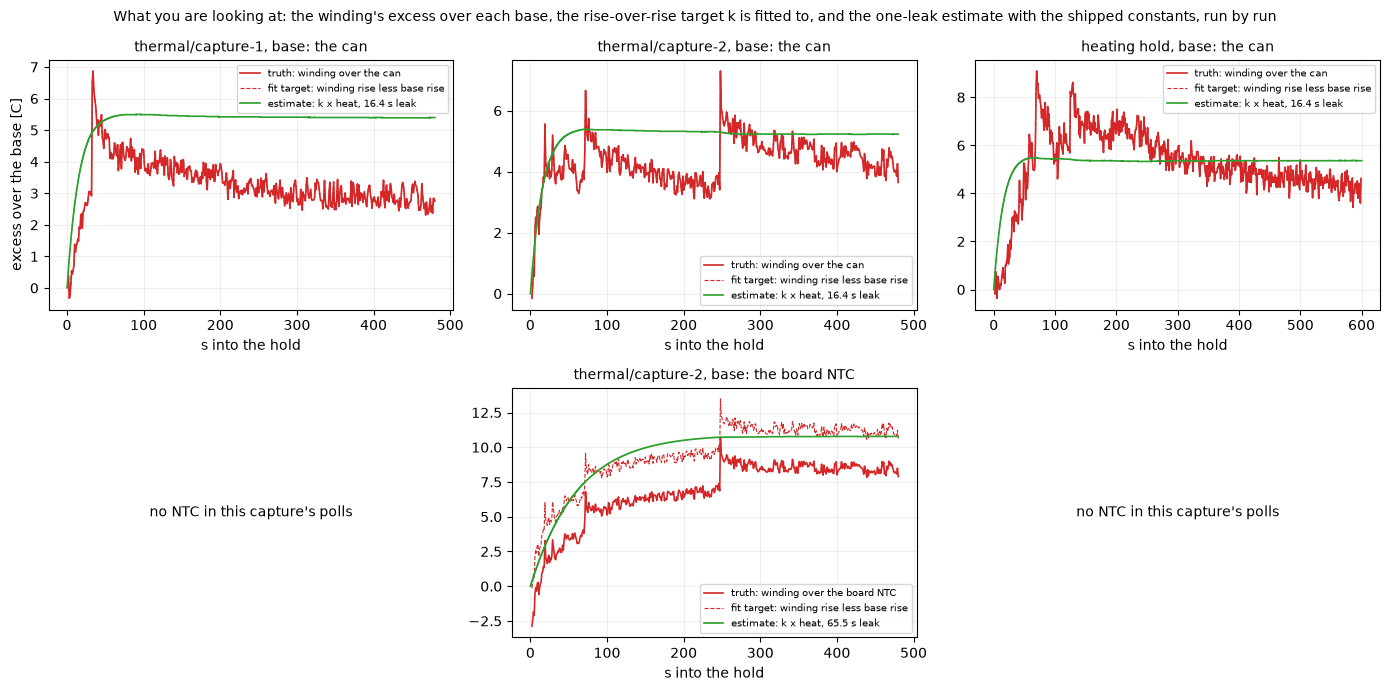

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, (name, R) in enumerate(RUNS.items()):
    for row, (base, shift, k) in enumerate((("can", CAN_SHIFT, K_CAN), ("ntc", NTC_SHIFT, K_NTC))):
        ax = axes[row, col]
        if R[base] is None:
            ax.text(0.5, 0.5, "no NTC in this capture's polls", ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()
            continue
        hq = i2t.heat(R["ig"].astype(np.int64), shift)
        est = i2t.rise_cc(hq, i2t.k_q16_of(k)) / 100                 # the kernel's integer rise
        ax.plot(R["tt"], R["tw"] - R[base], color="tab:red", lw=1.2, label=f"truth: winding over the {NAME[base]}")
        ax.plot(R["tt"], excess_rise(R, base), color="tab:red", lw=0.8, ls="--",
                label="fit target: winding rise less base rise")
        ax.plot(R["tg"], est, color="tab:green", lw=1.2, label=f"estimate: k x heat, {i2t.tau_s(shift):.1f} s leak")
        ax.set_title(f"{name}, base: the {NAME[base]}", fontsize=10)
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel("excess over the base [C]")
        ax.legend(fontsize=7)
        ax.set_xlabel("s into the hold")
fig.suptitle("What you are looking at: the winding's excess over each base, the rise-over-rise target k is fitted to, "
             "and the one-leak estimate with the shipped constants, run by run", fontsize=10)
plt.tight_layout()
plt.show()

## 4. The grade

The signed error of the estimate with the shipped constants against the truth $T_w$, over every run
that can grade the placement. The estimate is the shipped form, base plus rise, so the board NTC
row carries the NTC's rest offset against the can, and the table lists it as `rest offset C`. Cold
is the estimate under the copper reading, warm is over it.

In [10]:
rows = []
for name, R in RUNS.items():
    for base, shift, k in (("can", CAN_SHIFT, K_CAN), ("ntc", NTC_SHIFT, K_NTC)):
        if R[base] is None:
            continue
        x = R["tw"] - R[base]                                         # the truth: winding over the base
        est = np.interp(R["tt"], R["tg"], i2t.rise_cc(i2t.heat(R["ig"].astype(np.int64), shift), i2t.k_q16_of(k))) / 100
        lo, hi, rms = i2t.grade(est, x)
        e = est - x
        late = R["tt"] >= 120
        rows.append({"run": name, "NTC on the": base, "tau s": i2t.tau_s(shift), "k_q16": i2t.k_q16_of(k),
                     "rest offset C": R["base0"][base] - R["tw0"],
                     "cold C": lo, "coldest at s": float(R["tt"][np.argmin(e)]), "warm C": hi,
                     "warmest at s": float(R["tt"][np.argmax(e)]), "rms C": rms,
                     "cold after 120 s": float(e[late].min()), "warm after 120 s": float(e[late].max())})
GRADE = pd.DataFrame(rows)
display(GRADE.round(2))
for base in ("can", "ntc"):
    g = GRADE[GRADE["NTC on the"] == base]
    print(f"NTC on the {NAME[base]}: over the whole hold at most {-g['cold C'].min():.1f} C cold and {g['warm C'].max():.1f} C warm, "
          f"rms {rng(g['rms C'].min(), g['rms C'].max(), '.1f')} C; after 120 s at most {-g['cold after 120 s'].min():.1f} C cold "
          f"and {g['warm after 120 s'].max():.1f} C warm; coldest at {', '.join(f'{v:.0f}' for v in g['coldest at s'])} s, "
          f"warmest at {', '.join(f'{v:.0f}' for v in g['warmest at s'])} s")
g = GRADE[GRADE["NTC on the"] == "ntc"].iloc[0]
print(f"less its rest offset of {g['rest offset C']:+.2f} C, the board NTC row reads {g['cold C'] - g['rest offset C']:+.2f} C "
      f"at its coldest and {g['warm C'] - g['rest offset C']:+.2f} C at its warmest")

,run,NTC on the,tau s,k_q16,rest offset C,cold C,coldest at s,warm C,warmest at s,rms C,cold after 120 s,warm after 120 s
0,thermal/capture-1,can,16.38,505,0.00,-1.89,34.0,3.08,468.0,2.13,1.10,3.08
1,thermal/capture-2,can,16.38,505,0.00,-2.01,248.0,2.21,234.0,1.06,-2.01,2.21
2,thermal/capture-2,ntc,65.54,1042,2.74,-0.38,19.0,4.33,214.0,2.81,-0.03,4.33
3,heating hold,can,16.38,505,0.00,-3.61,70.0,3.62,18.0,1.22,-3.22,1.95


NTC on the can: over the whole hold at most 3.6 C cold and 3.6 C warm, rms 1.1 to 2.1 C; after 120 s at most 3.2 C cold and 3.1 C warm; coldest at 34, 248, 70 s, warmest at 468, 234, 18 s
NTC on the board NTC: over the whole hold at most 0.4 C cold and 4.3 C warm, rms 2.8 C; after 120 s at most 0.0 C cold and 4.3 C warm; coldest at 19 s, warmest at 214 s
less its rest offset of +2.74 C, the board NTC row reads -3.11 C at its coldest and +1.59 C at its warmest


With the NTC on the can the coldest points sit at 34 s, 248 s and 70 s. Those are capture-1's step,
capture-2's step and the heating hold's early peak, where the copper reads a rise the one leak does
not follow. The warmest points sit at 468 s and 234 s in the two ident holds, where the copper's
excess has fallen back and the estimate holds its level. In the heating hold the warmest point is
at 18 s, where the 16.4 s leak runs ahead of a copper reading that rises slowly at first. Over every
run the can estimate stays inside 3.6 C either way, and about one contact step of that is in the
truth.

On the dev board the estimate reads at most 0.38 C cold (at 19 s) and 4.33 C warm (at 214 s). Less
its 2.74 C rest offset the same row reads -3.11 to +1.59 C, the fit's own spread. So most of the warm
side is the two sensors disagreeing before the hold began, and section 7 asks which one is right.

For a protection constant I would propose a band of 5 C either way, the estimate never more than
5 C cold or warm against the copper reading over a hold at the rating, for either placement. Five
is the width the one-leak model holds on this motor with constants from three holds, with room for
the next unit and a contact step, and I make no accuracy claim beyond that. The real protection
margin sits in `i_cont` itself, since the I2t fold holds the current at the rating whatever the
estimate reads.

## 5. Across torque-off gaps

A hold grades the rise. The out-and-back reps of notebook 19 grade the fall. Each rep holds at the
low stop for 150 s, then leaves with torque off for 240 s, 30 s, 240 s, 30 s and 240 s before five
more 60 s holds at the same stop, logging the current every 12 ms the whole way. The winding has no
resistance reading with torque off, but after a 240 s gap it sits at the can (notebook 19's $T^*$),
so the can less the rest offset, minus the NTC, is the truth excess at the first base of holds 1, 3
and 5. That truth sits on the NTC's scale, so unlike section 4 it leaves the rest offset out. The
30 s gaps have no truth and are listed for the eye only.

In [11]:
rows = []
for c in ("oab/capture-1", "oab/capture-2"):
    log = tm.th_log(DS, c, "oab")
    m = tm.meter(DS, c)
    off = tm.rest_offset(tm.th_log(DS, c, "rest"), m)["offset"]
    t0 = log.t_unix.min()
    tg, ig = i2t.grid(log.t_unix.to_numpy() - t0, log.i.abs().to_numpy(), 0.0, log.t_unix.max() - t0)
    est = i2t.rise_cc(i2t.heat(ig.astype(np.int64), NTC_SHIFT), i2t.k_q16_of(K_NTC)) / 100
    for b in tm.bases(log).query("n == 0").itertuples():
        if b.hold == "hold0":
            continue
        gap = {"hold1": 240, "hold2": 30, "hold3": 240, "hold4": 30, "hold5": 240}[b.hold]
        truth = tm.can_at(m, b.t_unix) - off - b.t_ntc if gap == 240 else np.nan
        e = float(np.interp(b.t_unix - t0, tg, est))
        rows.append({"rep": c, "hold": b.hold, "gap before s": gap, "estimate excess C": e,
                     "truth T* - NTC C": truth, "error C": e - truth})
GAPS = pd.DataFrame(rows)
display(GAPS.round(2))
long, short = GAPS[GAPS["gap before s"] == 240], GAPS[GAPS["gap before s"] == 30]
print(f"after 240 s the {i2t.tau_s(NTC_SHIFT):.1f} s leak keeps {np.exp(-240 / i2t.tau_s(NTC_SHIFT)) * 100:.1f} % of the heat; "
      f"estimate {long['estimate excess C'].min():.2f} to {long['estimate excess C'].max():.2f} C, truth "
      f"{long['truth T* - NTC C'].min():.2f} to {long['truth T* - NTC C'].max():.2f} C, error "
      f"{long['error C'].min():+.2f} to {long['error C'].max():+.2f} C")
print(f"after 30 s it keeps {np.exp(-30 / i2t.tau_s(NTC_SHIFT)) * 100:.0f} %; estimate "
      f"{short['estimate excess C'].min():.2f} to {short['estimate excess C'].max():.2f} C")

,rep,hold,gap before s,estimate excess C,truth T* - NTC C,error C
0,oab/capture-1,hold1,240,0.82,0.84,-0.02
1,oab/capture-1,hold2,30,4.70,NaN,NaN
2,oab/capture-1,hold3,240,0.74,0.89,-0.15
3,oab/capture-1,hold4,30,4.13,NaN,NaN
4,oab/capture-1,hold5,240,0.76,0.82,-0.06
5,oab/capture-2,hold1,240,0.81,0.65,0.16
6,oab/capture-2,hold2,30,4.59,NaN,NaN
7,oab/capture-2,hold3,240,0.77,0.60,0.17
8,oab/capture-2,hold4,30,4.50,NaN,NaN
9,oab/capture-2,hold5,240,0.78,0.14,0.64


after 240 s the 65.5 s leak keeps 2.6 % of the heat; estimate 0.74 to 0.82 C, truth 0.14 to 0.89 C, error -0.15 to +0.64 C
after 30 s it keeps 63 %; estimate 4.13 to 4.70 C


After a 240 s gap the 65.5 s leak keeps 2.6 % of the heat, and the estimate sits 0.74 to 0.82 C over
the NTC while the can-derived truth says 0.14 to 0.89 C. The errors run from -0.15 to +0.64 C, the
largest on the last hold of the second rep, where the truth puts the winding 0.14 C over the NTC.
After a 30 s gap the leak keeps 63 % and the estimate still carries 4.13 to 4.70 C of the hold's
rise. That is right in direction, and there is no truth to say by how much.

## 6. What ships from this

The firmware keeps the I2t heat it already has, reads the NTC in centi-C as before, and adds the
rise. The host writes two constants per servo and board, and this table is what `ident write`
gets for the bench MG90 until the teardown refines it. The dev board's 65.5 s leak is written as
66 s, which the firmware rounds to shift 12. The firmware's seed for the dev board carries 1044, from
an earlier replay of these holds with four guard bits under the heat instead of five. The 0.2 %
between that and the 1042 here is far inside the fit's spread, so the seed stays.

In [12]:
ship = pd.DataFrame([
    {"NTC on the": "can (swap board)", "thermal_tau_s": thermal_tau_s(CAN_SHIFT), "shift": CAN_SHIFT,
     "th_rise_q016": i2t.k_q16_of(K_CAN), "k cC/count^2": K_CAN, "C/W it implies": cw(K_CAN)},
    {"NTC on the": "board in room air (dev board)", "thermal_tau_s": thermal_tau_s(NTC_SHIFT), "shift": NTC_SHIFT,
     "th_rise_q016": i2t.k_q16_of(K_NTC), "k cC/count^2": K_NTC, "C/W it implies": cw(K_NTC)},
]).set_index("NTC on the")
display(ship.round({"k cC/count^2": 5, "C/W it implies": 1}))
for label, row in ship.iterrows():
    print(f"{label}: thermal_tau_s {int(row.thermal_tau_s)} runs at shift {i2t.tau_shift(int(row.thermal_tau_s))}")
i_cont = 277                                                     # the bench MG90's 250 mA rating in counts
print(f"at i_cont {i_cont} counts the heat settles at {i_cont ** 2} counts^2: a rise of "
      f"{i2t.rise_cc([i_cont ** 2], i2t.k_q16_of(K_CAN))[0] / 100:.1f} C over the can, "
      f"{i2t.rise_cc([i_cont ** 2], i2t.k_q16_of(K_NTC))[0] / 100:.1f} C over the board NTC")

,thermal_tau_s,shift,th_rise_q016,k cC/count^2,C/W it implies
NTC on the,,,,,
can (swap board),16,10,505,0.00771,21.0
board in room air (dev board),66,12,1042,0.01591,43.3


can (swap board): thermal_tau_s 16 runs at shift 10
board in room air (dev board): thermal_tau_s 66 runs at shift 12
at i_cont 277 counts the heat settles at 76729 counts^2: a rise of 5.9 C over the can, 12.2 C over the board NTC


The teardown changes one input. The winding's heat capacity sets how fast the first seconds of a
hold may rise, and with it known the early peaks of section 2 can be split into real heat and brush
contact. If the contact share is large, the truth excess over the can gets smaller and so does $k$.
That is a smaller rise constant, so the shipped one stays on the warm side until then.

## 7. What is open

Each item lists its candidates and the experiment that tells them apart. One of them leans on how
the aggregate R and the can move over the last five minutes of each hold, which the cell below
prints.

In [13]:
# the aggregate R and the can over the last five minutes of each hold: the 30 s mean at the end
# against the 30 s mean ending 300 s earlier
for name, R in RUNS.items():
    tt, end = R["tt"], R["tt"][-1]
    a, b = (tt > end - 330) & (tt <= end - 300), tt > end - 30
    dr = (np.nanmean(R["r"][b]) / np.nanmean(R["r"][a]) - 1) * 100
    dc = np.nanmean(R["can"][b]) - np.nanmean(R["can"][a])
    print(f"{name}: R moves {dr:+.2f} % ({dr / 100 * (K_CU + R['tw0']):+.1f} C of copper) and the can {dc:+.2f} C "
          f"from {end - 315:.0f} s to {end - 15:.0f} s")

thermal/capture-1: R moves +0.40 % (+1.0 C of copper) and the can +1.92 C from 165 s to 465 s
thermal/capture-2: R moves +0.92 % (+2.4 C of copper) and the can +2.21 C from 165 s to 465 s
heating hold: R moves -0.21 % (-0.5 C of copper) and the can +0.71 C from 284 s to 584 s


- **The board NTC and the can disagree at rest.** Before capture-2's hold the board NTC read 2.74 C
  over the can bead, and that offset carries through the board NTC row of the grade (section 4).
  Notebook 19 found the same disagreement and could not say which sensor is right. The firmware's
  base carries the offset at rest, so if the can is right the dev board's estimate starts every hold
  2.74 C warm. Candidates: (a) the NTC reads high (its curve, or the board's own heat), (b) the bead
  reads low (its contact on the can, or its junction), (c) both read right and the board sits warmer
  than the servo at rest. A reference thermometer clamped beside the bead, with the board NTC logged
  at rest, tells them apart. (a) puts the reference on the bead's reading, (b) puts it on the NTC's,
  and (c) puts it on the bead's with a second reference on the board reading the NTC's.
- **Capture-2's first seconds rise faster than the winding's heat capacity allows.** Its copper
  rises 3.17 C from 2 to 10 s, where 0.260 W into notebook 18's 1.3 to 0.7 J/C allows 1.60 to 2.97 C
  with no heat leaving. Capture-1 and the heating hold stay inside their allowances, at 1.10 and
  0.29 C. Candidates: (a) brush contact resistance rising as the contact spot heats under current,
  which copper then reads as winding, (b) the 1 to 3 s reference window catching the contact still
  settling (the shipped thermometer's own note says every seated hold fell 0.4 to 0.9 % through its
  first second), (c) a heat capacity under the bracket. The teardown tells (c) from the rest. (a)
  from (b) wants a hold with the reference window at 5 to 7 s, which (b) predicts flattens the early
  rise and (a) does not.
- **The excess over the can peaks early and falls back.** It peaks inside the first 120 s at 6.9 C
  (34 s), 6.7 C (72 s) and 9.1 C (70 s) and ends at 2.7 to 4.6 C. A two-node plant holds its fast
  node up. In capture-1 the peak sits one second after the largest step of R. The same contact
  candidates cover it. A bead on a second spot of the can would say whether the can's own gradient
  is in it.
- **Winding to can reads 13.0 to 21.0 C/W here, against 28 to 45 in notebook 18.** The winding to
  the room reads 40.4 to 45.6 C/W against notebook 18's 57.1 to 71.4. The same locked hold is in
  both notebooks. Notebook 18 took its number from the can's fitted dynamics with the winding's heat
  capacity tied to it. This notebook reads it straight off the winding's excess. Over the last five
  minutes of the heating hold the aggregate R moves -0.21 %, half a degree of copper, while the can
  rises 0.71 C. The two ident holds move +0.40 % and +0.92 % over the same stretch, with capture-2's
  248 s step inside it. If the end excess carries a negative contact drift, the direct read is low
  and notebook 18 is nearer. A hold at half the current would cut the heat to a quarter and leave
  the contact drift where it is. Until then the two brackets stand side by side.
- **One run grades the dev board placement.** Capture-1 has no NTC in its polls. A second ident
  thermal hold with the NTC logged is the cheapest repeat, and the bench gate of the firmware band
  will be that run.
- **The cool-down has no copper truth.** The heating dataset's bursts every 60 s after its hold
  scatter 2 % of R, 5 C, as notebook 18 already found, so the fall is graded by the can alone
  (section 5). A locked hold with a short aggregate pulse every 30 s during the cool-down would read
  the winding's fall through the same ratio as the rise.

## Caveats

The truth is copper through a brush contact, so it carries the contact's steps, up to 1.44 % of R,
3.7 C, in one second on these holds, and the grade can only be as honest as that. The constants are
one motor on one board, and the dev board's NTC is a board thermometer in room air that read 2.74 C
over the can at rest. The swap board's NTC will sit inside the case, nearer the can than this, and
its constants need their own hold once the board exists. The leak is a power of two, so a user's
`thermal_tau_s` runs at the nearest octave. The firmware rounds up only above 1.5 times an octave,
so a written value can run a leak up to a factor of 1.5 shorter than written. Past 393 s the cap
holds it at 262 s.

The estimate is for protection. Nothing in it reads the winding to a degree, and nothing in the
firmware claims to.

## What is next

The firmware strip comes next, with this replay as the golden for its sim pin, then a heating hold
on the bench with the shipped estimate in the telemetry and this notebook's truth read over it. If
you run the hold on another servo, `oscnb.i2t` and the two loaders above are all it takes to get
its constants. Let me know what the teardown weighs.